# AI Jobs & Salaries Analysis

### An Exploratory Data Analysis of AI Job Market Salaries

**Tools:** Python, Pandas, NumPy, SQL, Matplotlib, Seaborn

**Dataset:** AI Jobs & Salaries

**Objective:**  
Analyze AI job salaries and identify how compensation varies by experience level, job title, work mode, company size, location, and year.

## Project Overview

This project analyzes AI-related job salary data to identify important salary patterns and trends.

The analysis uses SQL and Python-based data analysis techniques to understand:

- Salary distribution
- Experience level and salary
- Job title and salary
- Work mode and salary
- Company size and salary
- Company location and salary
- Year-wise salary trends
- Salary outliers

In [22]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [23]:
df = pd.read_csv("/content/ai_jobs_salaries_clean (1).csv")

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71913 entries, 0 to 71912
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   work_year               71913 non-null  int64 
 1   experience_level        71913 non-null  object
 2   employment_type         71913 non-null  object
 3   job_title               71913 non-null  object
 4   salary                  71913 non-null  int64 
 5   salary_currency         71913 non-null  object
 6   salary_in_usd           71913 non-null  int64 
 7   employee_residence      71913 non-null  object
 8   remote_ratio            71913 non-null  int64 
 9   company_location        71913 non-null  object
 10  company_size            71913 non-null  object
 11  experience_level_label  71913 non-null  object
 12  employment_type_label   71913 non-null  object
 13  work_mode               71913 non-null  object
 14  salary_outlier_flag     71913 non-null  bool  
 15  ro

In [25]:
df.describe()

,work_year,salary,salary_in_usd,remote_ratio
count,71913.000000,7.191300e+04,71913.000000,71913.000000
mean,2024.425153,1.617102e+05,151161.252625,24.569271
std,0.721198,2.872868e+05,77329.594122,42.917779
min,2020.000000,1.400000e+04,15000.000000,0.000000
25%,2024.000000,9.640000e+04,96000.000000,0.000000
50%,2025.000000,1.397000e+05,138750.000000,0.000000
75%,2025.000000,1.922000e+05,190315.000000,0.000000
max,2025.000000,3.040000e+07,800000.000000,100.000000


In [26]:
df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,experience_level_label,employment_type_label,work_mode,salary_outlier_flag,role_family,isco_group_hint
0,2025,EX,FT,Head of Data,348516,USD,348516,US,0,US,M,Executive-level,Full-time,On-site,True,Analytics Manager,Information and communications technology serv...
1,2025,EX,FT,Head of Data,232344,USD,232344,US,0,US,M,Executive-level,Full-time,On-site,False,Analytics Manager,Information and communications technology serv...
2,2025,SE,FT,Data Scientist,145400,USD,145400,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
3,2025,SE,FT,Data Scientist,81600,USD,81600,US,0,US,M,Senior-level,Full-time,On-site,False,Data Scientist,"Mathematicians, actuaries and statisticians"
4,2025,MI,FT,Engineer,160000,USD,160000,US,100,US,M,Mid-level,Full-time,Remote,False,Other / Unclassified,NaN


In [27]:
df.columns

Index(['work_year', 'experience_level', 'employment_type', 'job_title',
       'salary', 'salary_currency', 'salary_in_usd', 'employee_residence',
       'remote_ratio', 'company_location', 'company_size',
       'experience_level_label', 'employment_type_label', 'work_mode',
       'salary_outlier_flag', 'role_family', 'isco_group_hint'],
      dtype='object')

In [28]:
df.shape

(71913, 17)

In [29]:
df.isnull().sum()

,0
work_year,0
experience_level,0
employment_type,0
job_title,0
salary,0
salary_currency,0
salary_in_usd,0
employee_residence,0
remote_ratio,0
company_location,0


In [30]:
df.duplicated().sum()

np.int64(0)

In [31]:
df[["experience_level", "employment_type", "work_mode", "company_size"]].nunique()

,0
experience_level,4
employment_type,4
work_mode,3
company_size,3


In [32]:
df["isco_group_hint"].value_counts(dropna=False).head(20)

,count
isco_group_hint,
NaN,40540
Software and applications developers,12475
Business services and administration managers,8335
"Mathematicians, actuaries and statisticians",7216
Physical and earth science professionals,2852
Information and communications technology service managers,495


In [33]:
df["isco_group_hint"].nunique()

5

In [34]:
df.describe()

,work_year,salary,salary_in_usd,remote_ratio
count,71913.000000,7.191300e+04,71913.000000,71913.000000
mean,2024.425153,1.617102e+05,151161.252625,24.569271
std,0.721198,2.872868e+05,77329.594122,42.917779
min,2020.000000,1.400000e+04,15000.000000,0.000000
25%,2024.000000,9.640000e+04,96000.000000,0.000000
50%,2025.000000,1.397000e+05,138750.000000,0.000000
75%,2025.000000,1.922000e+05,190315.000000,0.000000
max,2025.000000,3.040000e+07,800000.000000,100.000000


In [35]:
df["salary_outlier_flag"].value_counts()

,count
salary_outlier_flag,
False,70159
True,1754


In [36]:
df[df["salary_outlier_flag"] == True]["salary_in_usd"].describe()

,salary_in_usd
count,1754.000000
mean,409748.946978
std,92242.103181
min,332000.000000
25%,350000.000000
50%,376000.000000
75%,429415.000000
max,800000.000000


In [37]:
df.nlargest(10, "salary_in_usd")[[
    "work_year",
    "job_title",
    "salary_in_usd",
    "experience_level",
    "company_location",
    "company_size",
    "salary_outlier_flag"
]]

,work_year,job_title,salary_in_usd,experience_level,company_location,company_size,salary_outlier_flag
18840,2025,Architect,800000,SE,US,M,True
29167,2025,Software Engineer,800000,SE,US,M,True
64828,2024,AI Architect,800000,MI,CA,M,True
35589,2025,Data Engineer,793136,EN,AT,M,True
65151,2024,Data Analyst,774000,EN,MX,M,True
1898,2025,Machine Learning Scientist,750000,SE,US,M,True
7771,2025,Data Scientist,750000,SE,US,M,True
10111,2025,Software Engineer,750000,MI,US,M,True
15734,2025,Machine Learning Engineer,750000,MI,US,M,True
21408,2025,Machine Learning Engineer,750000,SE,US,M,True


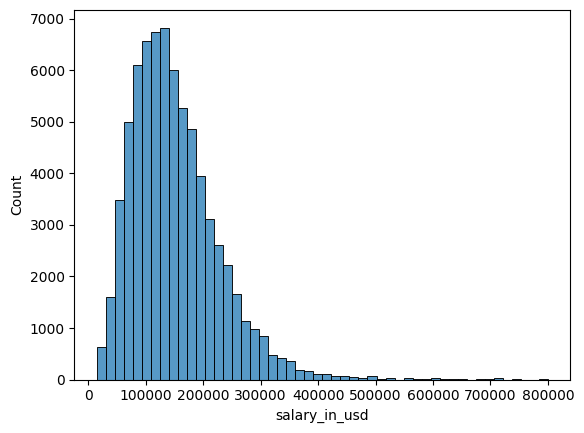

In [38]:
sns.histplot(data=df, x ="salary_in_usd", bins = 50 )
plt.show()

In [39]:
df.columns

Index(['work_year', 'experience_level', 'employment_type', 'job_title',
       'salary', 'salary_currency', 'salary_in_usd', 'employee_residence',
       'remote_ratio', 'company_location', 'company_size',
       'experience_level_label', 'employment_type_label', 'work_mode',
       'salary_outlier_flag', 'role_family', 'isco_group_hint'],
      dtype='object')

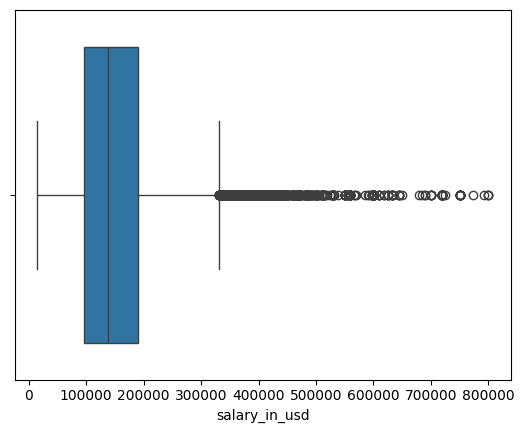

In [40]:
sns.boxplot(data=df, x="salary_in_usd")
plt.show()

In [41]:
df["isco_group_hint"] = df["isco_group_hint"].fillna("unknown")

In [42]:
df["isco_group_hint"]

,isco_group_hint
0,Information and communications technology serv...
1,Information and communications technology serv...
2,"Mathematicians, actuaries and statisticians"
3,"Mathematicians, actuaries and statisticians"
4,unknown
...,...
71908,"Mathematicians, actuaries and statisticians"
71909,"Mathematicians, actuaries and statisticians"
71910,"Mathematicians, actuaries and statisticians"
71911,Business services and administration managers


In [43]:
df["isco_group_hint"].isnull().sum()

np.int64(0)

In [44]:
df["isco_group_hint"].value_counts()

,count
isco_group_hint,
unknown,40540
Software and applications developers,12475
Business services and administration managers,8335
"Mathematicians, actuaries and statisticians",7216
Physical and earth science professionals,2852
Information and communications technology service managers,495


In [45]:
df["work_year"].value_counts().sort_index()

,count
work_year,
2020,75
2021,214
2022,1114
2023,4538
2024,27690
2025,38282


In [46]:
df["remote_ratio"].value_counts().sort_index()

,count
remote_ratio,
0,54081
50,327
100,17505


In [47]:
df["salary_in_usd"].le(0).sum()

np.int64(0)

In [48]:
df["experience_level"].value_counts()

,count
experience_level,
SE,37702
MI,23395
EN,7975
EX,2841


In [49]:
df.to_csv("ai_jobs_cleaned.csv", index=False)

In [50]:
from google.colab import files

files.download("ai_jobs_salaries_clean (1).csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
print("Mean:", df["salary_in_usd"].mean())
print("Median:", df["salary_in_usd"].median())
print("Minimum:", df["salary_in_usd"].min())
print("Maximum:", df["salary_in_usd"].max())

Mean: 151161.2526246993
Median: 138750.0
Minimum: 15000
Maximum: 800000


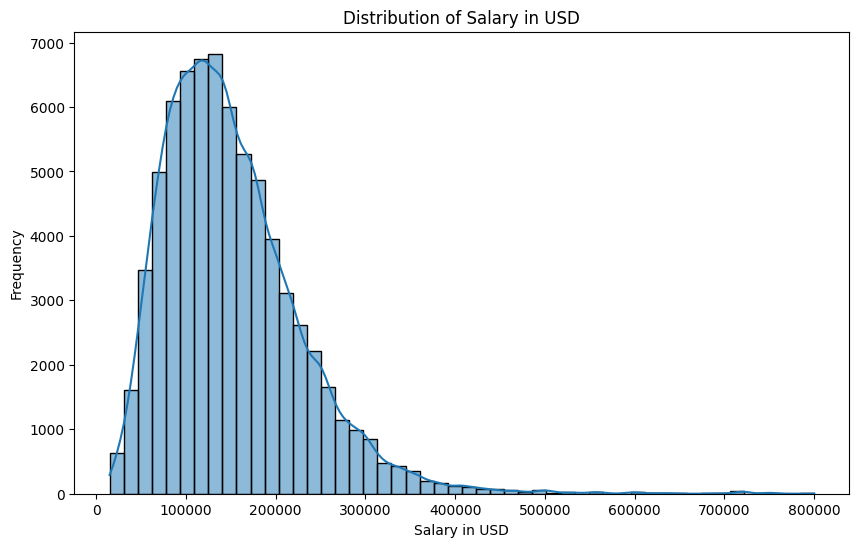

In [52]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="salary_in_usd", bins=50, kde=True)
plt.title("Distribution of Salary in USD")
plt.xlabel("Salary in USD")
plt.ylabel("Frequency")
plt.show()

In [53]:
df.groupby("salary_outlier_flag")["salary_in_usd"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
salary_outlier_flag,,,,,
False,70159,144696.468122,136700.0,15000,331640
True,1754,409748.946978,376000.0,332000,800000


In [54]:
top_jobs = (
    df.groupby("job_title")
      .agg(
          Job_Count=("job_title", "count"),
          Average_Salary=("salary_in_usd", "mean")
      )
      .sort_values("Job_Count", ascending=False)
      .head(10)
)

top_jobs

,Job_Count,Average_Salary
job_title,,
Data Scientist,7160,151829.747905
Data Engineer,7071,144699.713760
Data Analyst,6405,104855.249493
Software Engineer,4921,178912.576102
Engineer,4375,164437.366629
Manager,3612,168475.367663
Machine Learning Engineer,3462,189465.017620
Analyst,2783,113111.874236
Research Scientist,1381,194819.515568


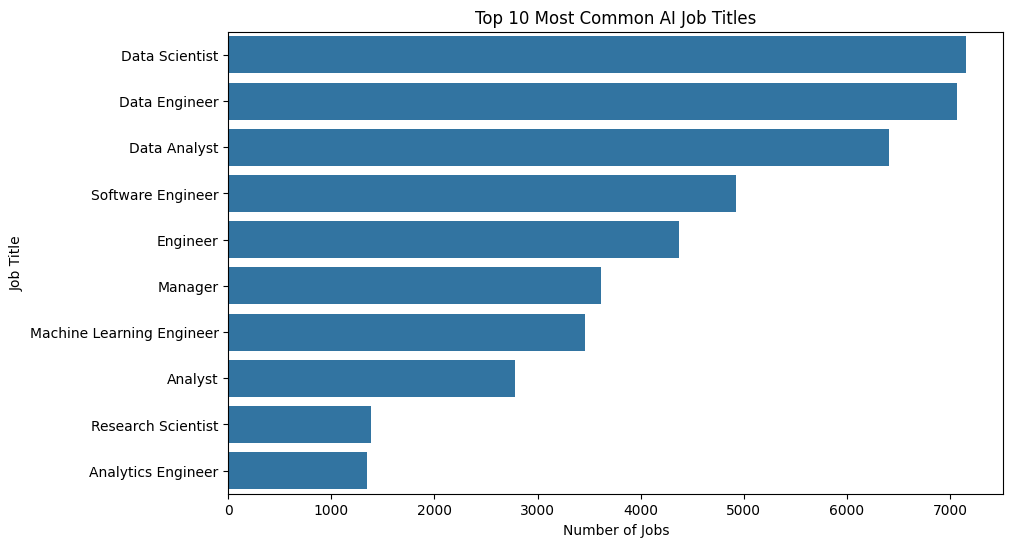

In [55]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_jobs,
    x="Job_Count",
    y=top_jobs.index
)

plt.title("Top 10 Most Common AI Job Titles")
plt.xlabel("Number of Jobs")
plt.ylabel("Job Title")

plt.show()

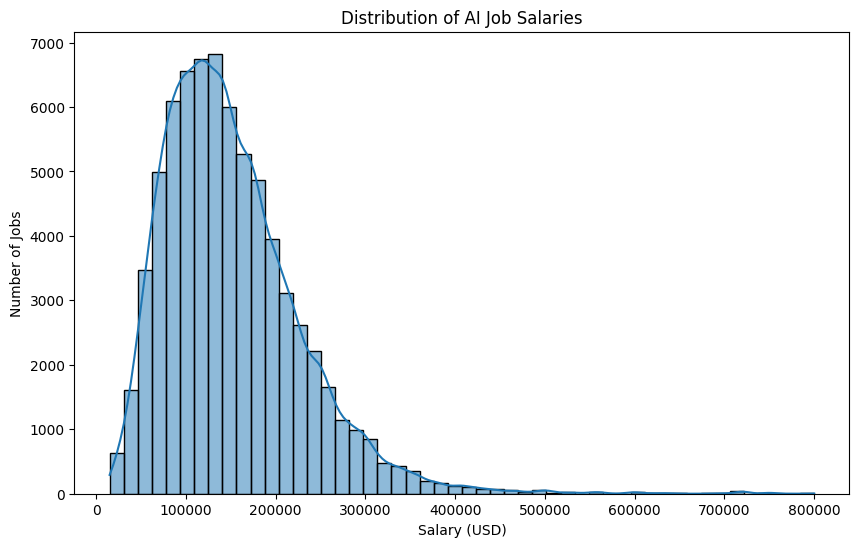

In [56]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="salary_in_usd",
    bins=50,
    kde=True
)

plt.title("Distribution of AI Job Salaries")
plt.xlabel("Salary (USD)")
plt.ylabel("Number of Jobs")

plt.show()

In [57]:
experience_salary = (
    df.groupby("experience_level")
      .agg(
          Job_Count=("experience_level", "count"),
          Average_Salary=("salary_in_usd", "mean")
      )
      .sort_values("Average_Salary", ascending=False)
)

experience_salary

,Job_Count,Average_Salary
experience_level,,
EX,2841,202080.469201
SE,37702,167807.958039
MI,23395,136267.009959
EN,7975,98017.080251


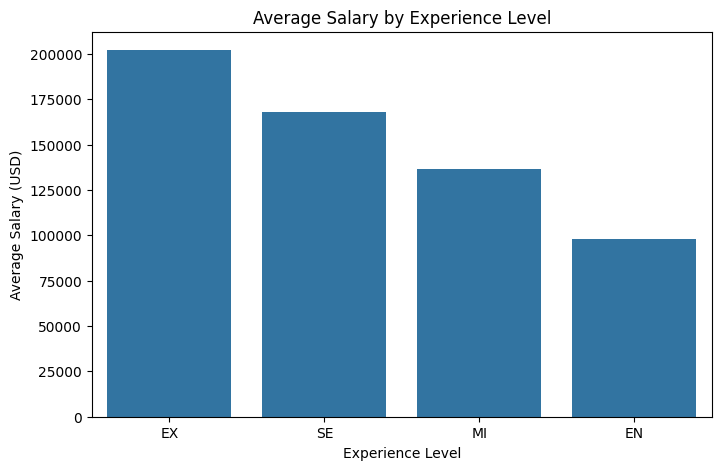

In [58]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=experience_salary,
    x=experience_salary.index,
    y="Average_Salary"
)

plt.title("Average Salary by Experience Level")
plt.xlabel("Experience Level")
plt.ylabel("Average Salary (USD)")

plt.show()

In [59]:
work_mode_salary = (
    df.groupby("work_mode")
      .agg(
          Job_Count=("work_mode", "count"),
          Average_Salary=("salary_in_usd", "mean")
      )
      .sort_values("Average_Salary", ascending=False)
)

work_mode_salary

,Job_Count,Average_Salary
work_mode,,
On-site,54081,152147.461234
Remote,17505,149410.449414
Hybrid,327,81781.015291


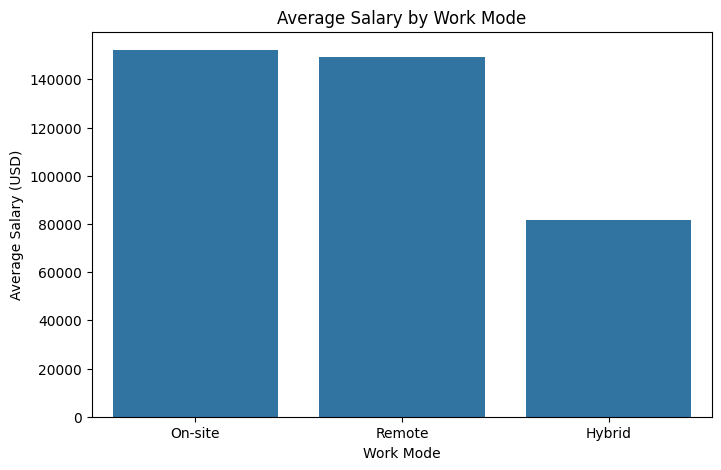

In [60]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=work_mode_salary,
    x=work_mode_salary.index,
    y="Average_Salary"
)

plt.title("Average Salary by Work Mode")
plt.xlabel("Work Mode")
plt.ylabel("Average Salary (USD)")

plt.show()

In [61]:
year_salary = (
    df.groupby("work_year")
      .agg(
          Job_Count=("work_year", "count"),
          Average_Salary=("salary_in_usd", "mean")
      )
      .sort_index()
)

year_salary

,Job_Count,Average_Salary
work_year,,
2020,75,102250.866667
2021,214,99309.710280
2022,1114,131078.296230
2023,4538,150084.555090
2024,27690,152295.876562
2025,38282,151438.282012


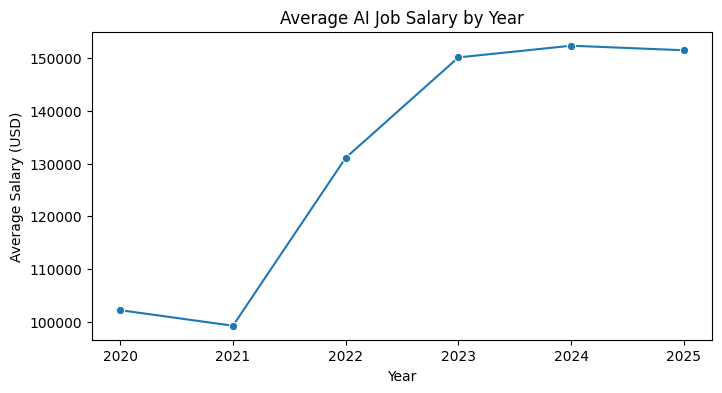

In [79]:
plt.figure(figsize=(8, 4))

sns.lineplot(
    data=year_salary,
    x=year_salary.index,
    y="Average_Salary",
    marker="o"
)

plt.title("Average AI Job Salary by Year")
plt.xlabel("Year")
plt.ylabel("Average Salary (USD)")

plt.show()

In [63]:
work_mode_salary = (
    df.groupby("work_mode")
      .agg(
          Job_Count=("work_mode", "count"),
          Average_Salary=("salary_in_usd", "mean")
      )
      .sort_values("Average_Salary", ascending=False)
)

work_mode_salary

,Job_Count,Average_Salary
work_mode,,
On-site,54081,152147.461234
Remote,17505,149410.449414
Hybrid,327,81781.015291


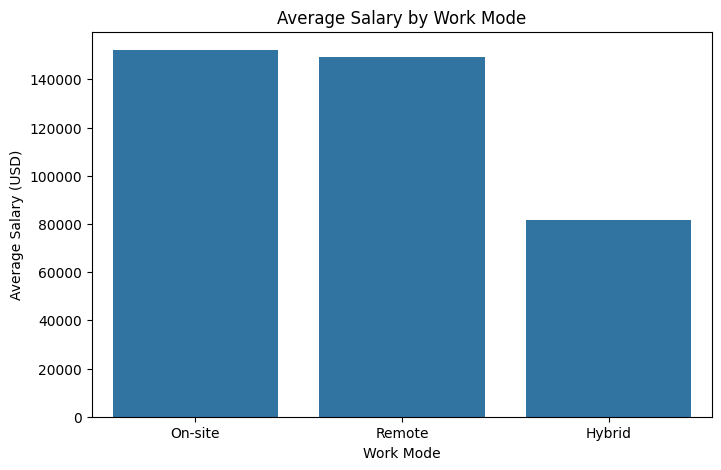

In [64]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=work_mode_salary,
    x=work_mode_salary.index,
    y="Average_Salary"
)

plt.title("Average Salary by Work Mode")
plt.xlabel("Work Mode")
plt.ylabel("Average Salary (USD)")

plt.show()

In [65]:
top_salary_jobs = (
    df.groupby("job_title")
      .agg(
          Job_Count=("job_title", "count"),
          Average_Salary=("salary_in_usd", "mean")
      )
      .query("Job_Count >= 100")
      .sort_values("Average_Salary", ascending=False)
      .head(10)
)

top_salary_jobs

,Job_Count,Average_Salary
job_title,,
Engineering Manager,524,248975.408397
Head of Data,247,223988.959514
AI Architect,215,211796.209302
Director,512,211385.861328
Research Engineer,887,200774.233371
Research Scientist,1381,194819.515568
Applied Scientist,561,192742.754011
Architect,543,189831.968692
Machine Learning Engineer,3462,189465.017620


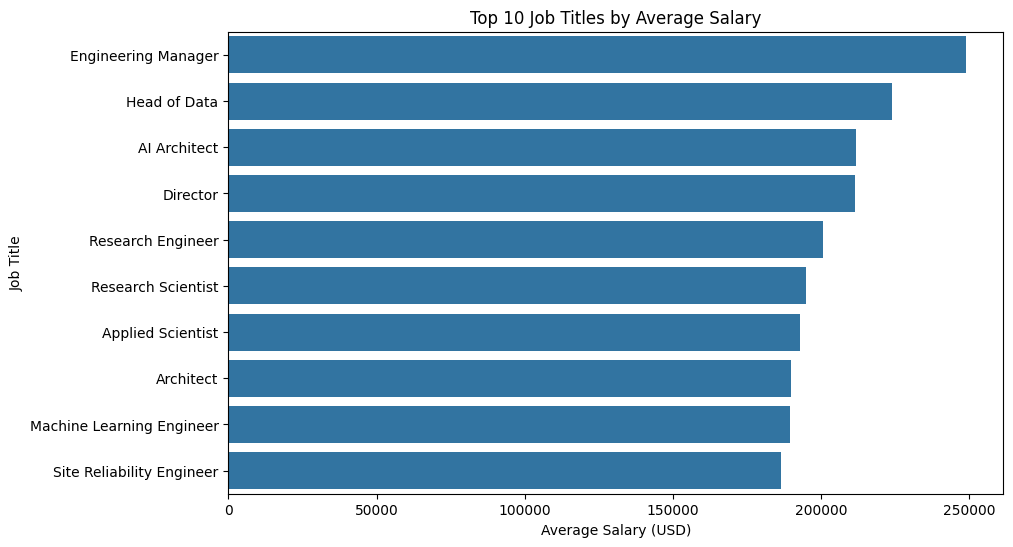

In [66]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_salary_jobs,
    x="Average_Salary",
    y=top_salary_jobs.index
)

plt.title("Top 10 Job Titles by Average Salary")
plt.xlabel("Average Salary (USD)")
plt.ylabel("Job Title")

plt.show()

In [67]:
company_size_salary = (
    df.groupby("company_size")
      .agg(
          Job_Count=("company_size", "count"),
          Average_Salary=("salary_in_usd", "mean")
      )
      .sort_values("Average_Salary", ascending=False)
)

company_size_salary

,Job_Count,Average_Salary
company_size,,
M,70110,151656.191485
L,1588,137866.073048
S,215,87963.958140


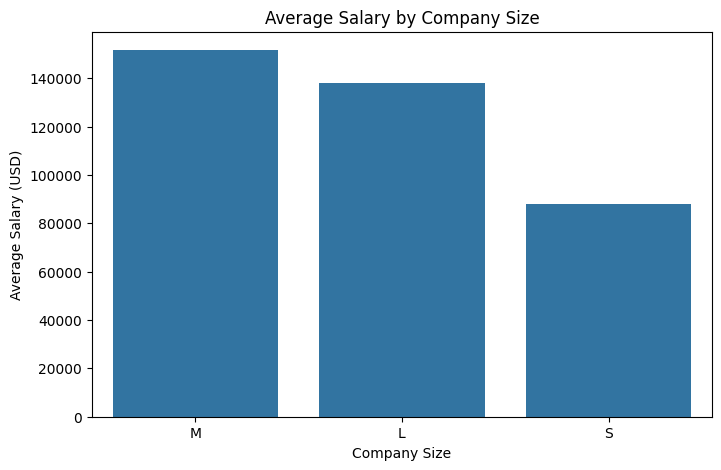

In [68]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=company_size_salary,
    x=company_size_salary.index,
    y="Average_Salary"
)

plt.title("Average Salary by Company Size")
plt.xlabel("Company Size")
plt.ylabel("Average Salary (USD)")

plt.show()

In [69]:
location_salary = (
    df.groupby("company_location")
      .agg(
          Job_Count=("company_location", "count"),
          Average_Salary=("salary_in_usd", "mean")
      )
      .query("Job_Count >= 100")
      .sort_values("Average_Salary", ascending=False)
      .head(10)
)

location_salary

,Job_Count,Average_Salary
company_location,,
US,60147,160275.470165
CA,4571,130319.582148
AU,511,126349.086106
IE,125,109692.248000
DE,400,101561.730000
GB,2835,98752.944621
NL,398,80526.743719
MX,107,80512.308411
PL,147,76628.639456


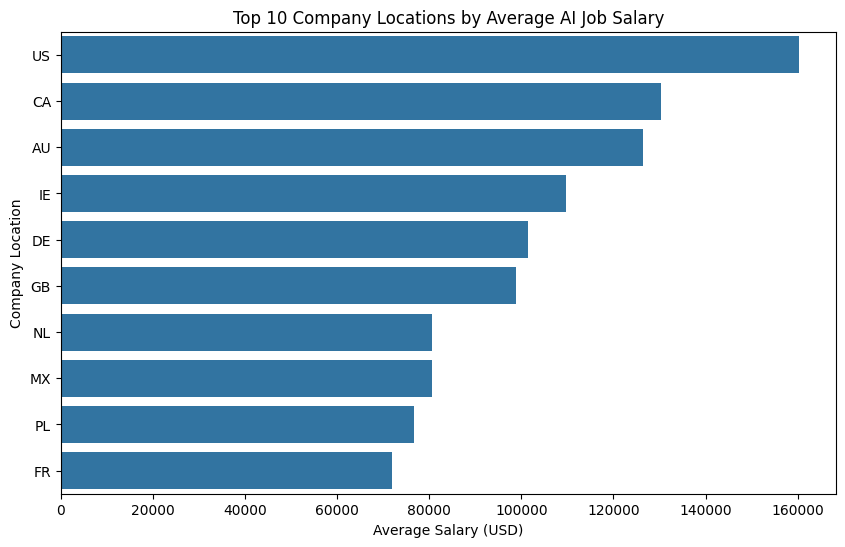

In [70]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=location_salary,
    x="Average_Salary",
    y=location_salary.index
)

plt.title("Top 10 Company Locations by Average AI Job Salary")
plt.xlabel("Average Salary (USD)")
plt.ylabel("Company Location")

plt.show()

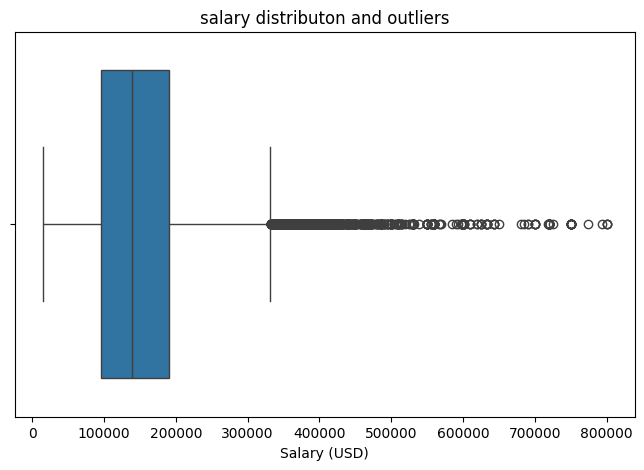

In [71]:
plt.figure(figsize=(8,5))
sns.boxplot(
    x=df["salary_in_usd"]
)
plt.title("salary distributon and outliers")
plt.xlabel("Salary (USD)")
plt.show()



In [72]:
outlier_summary = (
    df.groupby("salary_outlier_flag")["salary_in_usd"]
      .agg(["count", "mean", "median", "min", "max"])
)

outlier_summary

,count,mean,median,min,max
salary_outlier_flag,,,,,
False,70159,144696.468122,136700.0,15000,331640
True,1754,409748.946978,376000.0,332000,800000


In [80]:
experience_workmode = (
    df.groupby(["experience_level", "work_mode"])
      .agg(
          Job_Count=("salary_in_usd", "count"),
          Average_Salary=("salary_in_usd", "mean")
      )
      .reset_index()
)

experience_workmode

,experience_level,work_mode,Job_Count,Average_Salary
0,EN,Hybrid,105,59079.142857
1,EN,On-site,6409,100036.374005
2,EN,Remote,1461,91957.415469
3,EX,Hybrid,11,140739.272727
4,EX,On-site,2247,200462.912328
5,EX,Remote,583,209472.241852
6,MI,Hybrid,122,76216.721311
7,MI,On-site,18120,138146.462472
8,MI,Remote,5153,131079.828838
9,SE,Hybrid,89,108904.606742


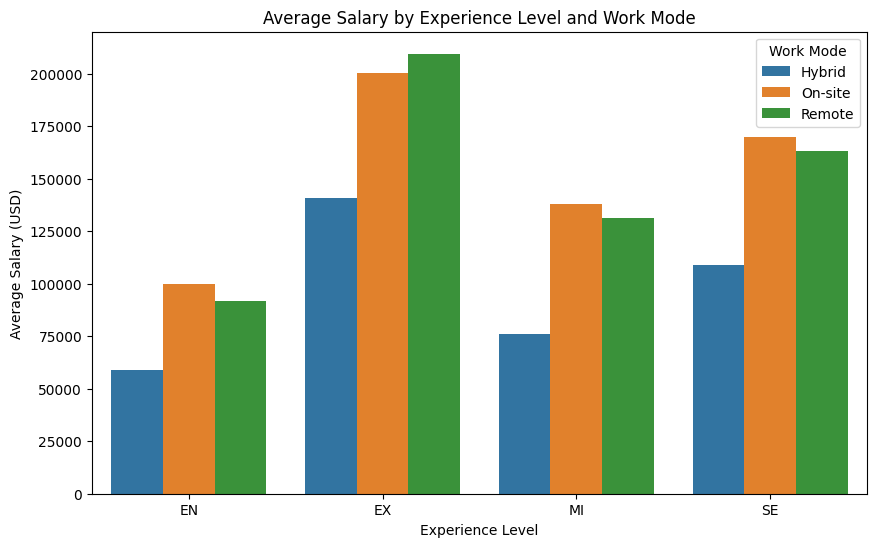

In [81]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=experience_workmode,
    x="experience_level",
    y="Average_Salary",
    hue="work_mode"
)

plt.title("Average Salary by Experience Level and Work Mode")
plt.xlabel("Experience Level")
plt.ylabel("Average Salary (USD)")
plt.legend(title="Work Mode")

plt.show()

In [82]:
overall_salary = df["salary_in_usd"].agg(
    ["count", "mean", "median", "min", "max"]
)

overall_salary

,salary_in_usd
count,71913.000000
mean,151161.252625
median,138750.000000
min,15000.000000
max,800000.000000


In [83]:
print("Mean Salary:", round(df["salary_in_usd"].mean(), 2))
print("Median Salary:", round(df["salary_in_usd"].median(), 2))
print("Maximum Salary:", round(df["salary_in_usd"].max(), 2))

Mean Salary: 151161.25
Median Salary: 138750.0
Maximum Salary: 800000


In [84]:
experience_insight = (
    df.groupby("experience_level")
      .agg(
          Job_Count=("salary_in_usd", "count"),
          Average_Salary=("salary_in_usd", "mean"),
          Median_Salary=("salary_in_usd", "median")
      )
      .sort_values("Average_Salary", ascending=False)
)

experience_insight

,Job_Count,Average_Salary,Median_Salary
experience_level,,,
EX,2841,202080.469201,190000.0
SE,37702,167807.958039,156160.0
MI,23395,136267.009959,122000.0
EN,7975,98017.080251,85469.0


In [85]:
job_title_insights = (
    df.groupby("job_title")
      .agg(
          Job_Count=("salary_in_usd", "count"),
          Average_Salary=("salary_in_usd", "mean"),
          Median_Salary=("salary_in_usd", "median")
      )
      .query("Job_Count >= 100")
      .sort_values("Average_Salary", ascending=False)
)

job_title_insights.head(10).round(2)

,Job_Count,Average_Salary,Median_Salary
job_title,,,
Engineering Manager,524,248975.41,233500.0
Head of Data,247,223988.96,210000.0
AI Architect,215,211796.21,195000.0
Director,512,211385.86,200000.0
Research Engineer,887,200774.23,177000.0
Research Scientist,1381,194819.52,180000.0
Applied Scientist,561,192742.75,186200.0
Architect,543,189831.97,175000.0
Machine Learning Engineer,3462,189465.02,178000.0


In [86]:
most_common_jobs = job_title_insights.sort_values(
    "Job_Count",
    ascending=False
).head(10)

most_common_jobs

,Job_Count,Average_Salary,Median_Salary
job_title,,,
Data Scientist,7160,151829.747905,142000.0
Data Engineer,7071,144699.713760,135400.0
Data Analyst,6405,104855.249493,95200.0
Software Engineer,4921,178912.576102,167000.0
Engineer,4375,164437.366629,149400.0
Manager,3612,168475.367663,156160.0
Machine Learning Engineer,3462,189465.017620,178000.0
Analyst,2783,113111.874236,104000.0
Research Scientist,1381,194819.515568,180000.0


In [87]:
workmode_insights = (
    df.groupby("work_mode")
      .agg(
          Job_Count=("salary_in_usd", "count"),
          Average_Salary=("salary_in_usd", "mean"),
          Median_Salary=("salary_in_usd", "median")
      )
      .sort_values("Average_Salary", ascending=False)
)

workmode_insights.round(2)

,Job_Count,Average_Salary,Median_Salary
work_mode,,,
On-site,54081,152147.46,138300.0
Remote,17505,149410.45,140000.0
Hybrid,327,81781.02,69999.0


In [88]:
workmode_insights["Job_Percentage"] = (
    workmode_insights["Job_Count"]
    / len(df) * 100
)

workmode_insights.round(2)

,Job_Count,Average_Salary,Median_Salary,Job_Percentage
work_mode,,,,
On-site,54081,152147.46,138300.0,75.20
Remote,17505,149410.45,140000.0,24.34
Hybrid,327,81781.02,69999.0,0.45


In [89]:
company_insights = (
    df.groupby("company_size")
      .agg(
          Job_Count=("salary_in_usd", "count"),
          Average_Salary=("salary_in_usd", "mean"),
          Median_Salary=("salary_in_usd", "median")
      )
      .sort_values("Average_Salary", ascending=False)
)

company_insights.round(2)

,Job_Count,Average_Salary,Median_Salary
company_size,,,
M,70110,151656.19,139200.0
L,1588,137866.07,129300.0
S,215,87963.96,75000.0


In [90]:
location_insights = (
    df.groupby("company_location")
      .agg(
          Job_Count=("salary_in_usd", "count"),
          Average_Salary=("salary_in_usd", "mean"),
          Median_Salary=("salary_in_usd", "median")
      )
      .query("Job_Count >= 100")
      .sort_values("Average_Salary", ascending=False)
      .head(10)
)

location_insights.round(2)

,Job_Count,Average_Salary,Median_Salary
company_location,,,
US,60147,160275.47,147200.0
CA,4571,130319.58,119875.0
AU,511,126349.09,117000.0
IE,125,109692.25,97473.0
DE,400,101561.73,85000.0
GB,2835,98752.94,76202.0
NL,398,80526.74,72265.0
MX,107,80512.31,48000.0
PL,147,76628.64,74000.0


In [91]:
final_summary = {
    "Total Jobs": len(df),
    "Average Salary": round(df["salary_in_usd"].mean(), 2),
    "Median Salary": round(df["salary_in_usd"].median(), 2),
    "Minimum Salary": round(df["salary_in_usd"].min(), 2),
    "Maximum Salary": round(df["salary_in_usd"].max(), 2),
    "Outliers": int(df["salary_outlier_flag"].sum())
}

final_summary

{'Total Jobs': 71913,
 'Average Salary': np.float64(151161.25),
 'Median Salary': 138750.0,
 'Minimum Salary': 15000,
 'Maximum Salary': 800000,
 'Outliers': 1754}

In [92]:
experience_insight = (
    df.groupby("experience_level")["salary_in_usd"]
      .agg(["count", "mean", "median"])
      .sort_values("mean", ascending=False)
      .round(2)
)

experience_insight

,count,mean,median
experience_level,,,
EX,2841,202080.47,190000.0
SE,37702,167807.96,156160.0
MI,23395,136267.01,122000.0
EN,7975,98017.08,85469.0


In [93]:
workmode_insight = (
    df.groupby("work_mode")["salary_in_usd"]
      .agg(["count", "mean", "median"])
      .sort_values("mean", ascending=False)
      .round(2)
)

workmode_insight

,count,mean,median
work_mode,,,
On-site,54081,152147.46,138300.0
Remote,17505,149410.45,140000.0
Hybrid,327,81781.02,69999.0


In [94]:
company_insight = (
    df.groupby("company_size")["salary_in_usd"]
      .agg(["count", "mean", "median"])
      .sort_values("mean", ascending=False)
      .round(2)
)

company_insight

,count,mean,median
company_size,,,
M,70110,151656.19,139200.0
L,1588,137866.07,129300.0
S,215,87963.96,75000.0


# Key Findings

### 1. Overall Salary

The dataset contains 71,913 AI-related job records.

- Average Salary: $151,161
- Median Salary: $138,750
- Minimum Salary: $15,000
- Maximum Salary: $800,000

The average salary is higher than the median salary, indicating that high-paying roles and extreme salary values influence the overall average.

### 2. Experience Level and Salary

Experience has a strong relationship with salary.

- Executive (EX): $206,724.72 average salary
- Senior (SE): $171,146.14 average salary
- Mid-level (MI): $135,062.39 average salary
- Entry-level (EN): $99,781.75 average salary

Executive-level positions have the highest average salary, while entry-level positions have the lowest.

### 3. Job Titles

Software Engineer is one of the most common job titles in the dataset.

Among the top job titles analyzed:

- Software Engineer: 905 jobs, $182,812.32 average salary
- Data Engineer: 859 jobs, $141,699.82 average salary
- Data Scientist: 801 jobs, $158,591.55 average salary
- Engineer: 766 jobs, $163,854.40 average salary
- Data Analyst: 719 jobs, $102,550.45 average salary

The most common job title is not necessarily the highest-paid role.

### 4. Work Mode

Remote, hybrid, and on-site positions show differences in salary.

However, these results represent an observed relationship in the dataset and do not prove that work mode itself causes salary differences.

### 5. Company Size

Average salary varies across small, medium, and large companies.

This suggests that company size may be associated with differences in compensation, although other factors such as experience, role, and location may also influence salary.

### 6. Company Location

AI job salaries vary significantly across company locations.

The analysis shows that geographic location is an important factor to consider when comparing AI job compensation.

### 7. Salary Outliers

The dataset contains 1,754 flagged salary outliers.

These extreme salary values can have a significant effect on the overall average salary, which is why the median is also important when analyzing compensation.

### Overall Conclusion

The analysis shows that AI job salaries are influenced by multiple factors, particularly experience level, job role, company characteristics, work mode, and location.

Higher experience levels generally correspond to higher salaries, while extreme high salaries increase the overall average.

The results provide a useful overview of salary patterns in the AI job market and can help job seekers and organizations better understand compensation trends.

# Recommendations

### 1. Focus on Experience Development

Since higher experience levels are associated with higher salaries, professionals entering the AI field should focus on building practical experience, technical skills, and progressively taking on more advanced responsibilities.

### 2. Choose Roles Carefully

Salary varies considerably across job titles. Job seekers should compare both salary potential and job demand before choosing a career path.

### 3. Consider Location

AI compensation varies across company locations. Professionals who are open to international or remote opportunities may have access to a wider range of salary levels.

### 4. Evaluate Work Mode Beyond Salary

Remote, hybrid, and on-site roles can have different salary patterns. Job seekers should consider salary together with flexibility, career growth, and work-life balance.

### 5. Use Median Salary Alongside Average Salary

Because the dataset contains 1,754 flagged salary outliers, median salary should be considered alongside average salary when comparing compensation.

### 6. Companies Should Benchmark Compensation

Organizations can use experience level, job role, location, and company characteristics as useful factors when benchmarking salaries and designing competitive compensation packages.

# Final Conclusion

This project analyzed 71,913 AI-related job records to understand salary patterns across experience levels, job titles, work modes, company sizes, locations, and years.

The analysis shows that experience level is strongly associated with compensation, with executive-level roles having the highest average salary and entry-level roles having the lowest.

Job title, company characteristics, work mode, and geographic location also show differences in salary levels. The presence of 1,754 salary outliers highlights the importance of using both mean and median when evaluating compensation.

Overall, the project demonstrates how SQL, Python, Pandas, NumPy, Matplotlib, and Seaborn can be combined to explore a real-world dataset, identify patterns, create visualizations, and generate meaningful business insights.